# One person

With a single person in front of the radar the problem is one-dimensional: find the range bin of the chest, demodulate its phase, and read two rates from it. Each of these steps has more than one reasonable choice, and the choices that look harmless (the strongest bin, the mean as static offset, a Welch estimate with short segments) are the ones that fail on a real ward. The multi-person methods A to F reuse every step described here.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=["#1b4965", "#c8553d", "#5c946e", "#8c6d9f"])})
from radar import cube, simulate, vitals
from radar.spatial import steering

person = simulate.Person(1.8, 0, rr=16, hr=72, resp_mm=1.2)       # shallow breathing
clutter = [(1.45, 0, 4.0), (3.2, 30, 3.0), (1.8, 0, 1.5)]     # bed rail, wall, bed under the chest
x, truth = simulate.simulate([person], duration=90, clutter=clutter, snr_db=20, seed=3)
cfg, fs, t = truth["config"], truth["config"].frame_rate, truth["t"]
rp = cube.compensate_aop(cube.range_fft(x))
rax = cfg.range_axis()

## Which range bin

The strongest bin of the range profile is usually not the chest. A bed rail or a wall reflects more than a person, and it does not move. Two remedies: remove what is static (subtract the slow-time mean, `cube.remove_static`), or rank the bins by what they do over time. `vitals.best_bin` band-passes the complex slow-time signal of every bin and channel to the breathing band and compares the power that is left: a bed or a wall has none, however strong its echo, and the bins next to the chest only get its leakage. For one person the channel axis can be averaged first (a beam at broadside); the function also returns the best single channel, which is what we used before forming beams.

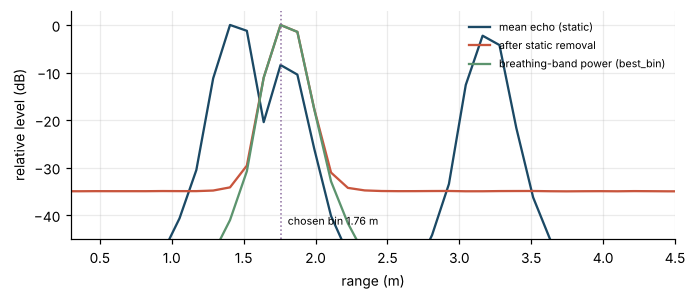

In [2]:
static = np.abs(rp.mean(axis=(0, 2))).mean(axis=0)
moving = np.abs(cube.remove_static(rp, axis=0)).mean(axis=(0, 1, 2))
b, ch, score = vitals.best_bin(rp.mean(axis=1, keepdims=True), fs)

fig, ax = plt.subplots(figsize=(6.4, 2.8))
db = lambda v: 20 * np.log10(v / v.max() + 1e-9)
ax.plot(rax, db(static), label="mean echo (static)")
ax.plot(rax, db(moving), label="after static removal")
ax.plot(rax[3:], db(score[0] ** 0.5), label="breathing-band power (best_bin)")
ax.axvline(rax[b], color="#8c6d9f", ls=":", lw=1)
ax.text(rax[b] + 0.05, -42, f"chosen bin {rax[b]:.2f} m", fontsize=7)
ax.set(xlim=(0.3, 4.5), ylim=(-45, 3), xlabel="range (m)", ylabel="relative level (dB)")
ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()

## Demodulation

The slow-time value of the chest bin is $z(t) = A\,e^{j4\pi x(t)/\lambda} + B$, where $B$ is everything static in the same bin, here the bed under the chest. In the complex plane $z$ traces an arc of a circle centred at $B$, not at the origin. Arctangent demodulation, $\angle z$, measures the angle seen from the origin; when $|B| > A$ the arc is seen from outside and the phase swing collapses.

Three ways to place the centre:

- the origin (no correction);
- the mean of $z$, right only when the arc closes into a full circle;
- a least-squares circle fit (`vitals.circle_fit`, algebraic fit of Kåsa), right for any arc length as long as the arc is longer than the noise.

Differentiate-and-cross-multiply (`vitals.dacm`) gives the same phase without the `unwrap` step, so an isolated noisy sample cannot introduce a $2\pi$ jump; it still needs the centre.

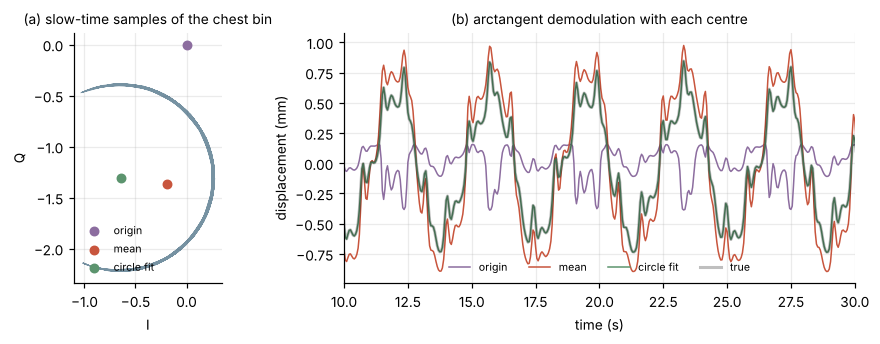

In [3]:
z = rp[:, :, :, b].mean(axis=(1, 2))
c_fit, radius = vitals.circle_fit(z)
true = 1e3 * (truth["displacement"][0] - truth["displacement"][0].mean())

fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.2), gridspec_kw={"width_ratios": [1, 1.7]})
ax[0].plot(z.real, z.imag, lw=0.4, color="#1b4965", alpha=0.6)
for c, lab, col in [(0, "origin", "#8c6d9f"), (z.mean(), "mean", "#c8553d"), (c_fit, "circle fit", "#5c946e")]:
    ax[0].scatter(np.real(c), np.imag(c), s=30, color=col, zorder=3, label=lab)
ax[0].set_aspect("equal")
ax[0].set(xlabel="I", ylabel="Q", title="(a) slow-time samples of the chest bin")
ax[0].legend(fontsize=7, loc="lower left")
for c, lab, col in [(0, "origin", "#8c6d9f"), (z.mean(), "mean", "#c8553d"), (c_fit, "circle fit", "#5c946e")]:
    d = 1e3 * vitals.displacement(z, cfg.wavelength, c)
    ax[1].plot(t, d, lw=1, color=col, label=lab)
ax[1].plot(t, true, color="k", lw=2, alpha=0.25, label="true")
ax[1].set(xlim=(10, 30), xlabel="time (s)", ylabel="displacement (mm)", title="(b) arctangent demodulation with each centre")
ax[1].legend(fontsize=7, ncol=4, loc="lower center")
plt.tight_layout()

## Which signal for which rate

The demodulated phase is proportional to the displacement. Breathing dominates it, and because breathing is not a sinusoid (the inhalation is faster than the exhalation), its harmonics at $2f_r, 3f_r, \dots$ reach into the heart band. Two other signals are common in our notebooks:

- the **phase rate**, $\dot\phi(t)/2\pi$, which is the chest velocity in disguise. Differentiation multiplies the spectrum by $2\pi f$, so the heartbeat at 1.2 Hz gains about five times over breathing at 0.27 Hz. Noise gains too, in proportion to frequency.
- the **amplitude** $|z(t)|$. With a static offset it oscillates with the breathing, which makes it a usable breathing signal when the phase is corrupted, but the relation is nonlinear: when the arc passes close to the line between origin and centre, the amplitude oscillates at twice the breathing rate.

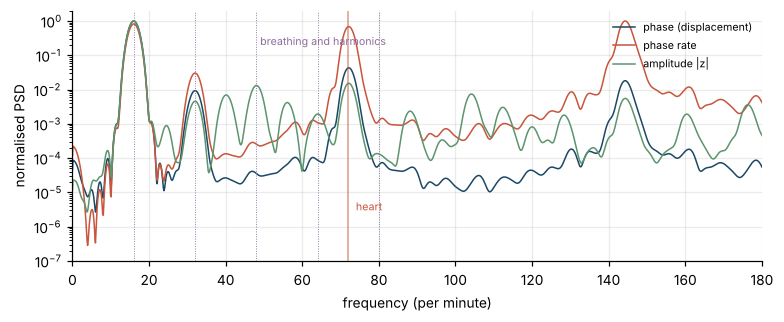

In [4]:
from scipy.signal import welch
ph = vitals.phase(z, c_fit)
sig = {"phase (displacement)": ph - ph.mean(),
       "phase rate": np.gradient(ph) * fs,
       "amplitude |z|": np.abs(z) - np.abs(z).mean()}
fig, ax = plt.subplots(figsize=(7.2, 3.0))
for k, (lab, s) in enumerate(sig.items()):
    f, p = welch(s, fs=fs, nperseg=int(30 * fs), nfft=8192)
    ax.semilogy(60 * f, p / p.max(), lw=1, label=lab)
for k in range(1, 6):
    ax.axvline(k * person.rr, color="#8c6d9f", lw=0.6, ls=":")
ax.text(person.rr * 3 + 1, 2e-1, "breathing and harmonics", fontsize=7, color="#8c6d9f")
ax.axvline(person.hr, color="#c8553d", lw=1.2, alpha=0.5)
ax.text(person.hr + 2, 3e-6, "heart", fontsize=7, color="#c8553d")
ax.set(xlim=(0, 180), ylim=(1e-7, 2), xlabel="frequency (per minute)", ylabel="normalised PSD")
ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()

## Reading a rate

`vitals` holds the rate finders used across the methods. They answer different questions and fail differently.

| Finder | Rate from | Fails when |
|---|---|---|
| `spectral_rate` | largest PSD peak in band, zero-padded and refined by a parabola | two peaks closer than the window resolves; a harmonic is stronger than the fundamental |
| `spectral_rate(..., harmonics=3)` | harmonic summation $\sum_k P(kf)/k$ | a breathing harmonic sits at half the heart rate (33 and 130 per minute, the asthma-attack setting): the heart then lends its power to the wrong candidate |
| `peak_count_rate` | median interval between peaks | prominence too low (double peaks) or too high (missed breaths) |
| `zero_crossing_rate` | crossings / 2 | the signal is not band-limited, every noise crossing counts |
| `autocorr_rate` | first strong autocorrelation lag | the period range admits a multiple of the true period |
| `ridge` | dynamic-programming ridge of a spectrogram | the rate jumps faster than the allowed step |

The spectral finder deserves a remark on resolution. The bin spacing of a Welch estimate is $f_s/n_{fft}$; with segments of 5 s and no zero padding it is 0.2 Hz, so every heart rate comes out as a multiple of 12 beats per minute. Zero padding interpolates the spectrum, and fitting a parabola to the log power around the maximum removes the grid. Neither adds resolution: whether two close components are separated still depends on the segment length, roughly $1/T$.

breathing, per minute (true 16 )
  spectral         16.0
  peak intervals   16.2
  zero crossings   16.0
  autocorrelation  16.0
heart, per minute (true 72 )
  spectral, 5 s    144.3
  harmonic sum     72.2


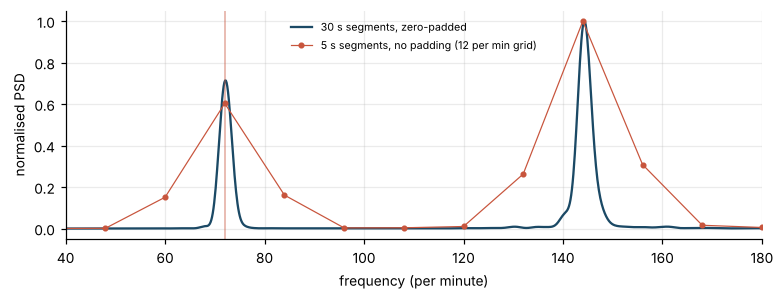

In [5]:
heart = vitals.bandpass(np.gradient(ph) * fs, fs, vitals.HR_BAND)
fig, ax = plt.subplots(figsize=(7.2, 2.8))
f5, p5 = welch(heart, fs=fs, nperseg=int(5 * fs))
f30, p30 = welch(heart, fs=fs, nperseg=int(30 * fs), nfft=8192)
ax.plot(60 * f30, p30 / p30.max(), label="30 s segments, zero-padded")
ax.plot(60 * f5, p5 / p5.max(), "o-", ms=3, lw=0.8, label="5 s segments, no padding (12 per min grid)")
ax.axvline(person.hr, color="#c8553d", lw=1, alpha=0.5)
ax.set(xlim=(40, 180), xlabel="frequency (per minute)", ylabel="normalised PSD")
ax.legend(fontsize=7)
plt.tight_layout()

resp = vitals.bandpass(ph, fs, vitals.RR_BAND)
print("breathing, per minute (true", person.rr, ")")
print("  spectral        ", round(vitals.spectral_rate(resp, fs, vitals.RR_BAND), 1))
print("  peak intervals  ", round(vitals.peak_count_rate(resp, fs, max_rate=42), 1))
print("  zero crossings  ", round(vitals.zero_crossing_rate(resp, fs), 1))
print("  autocorrelation ", round(vitals.autocorr_rate(resp, fs, vitals.RR_BAND), 1))
print("heart, per minute (true", person.hr, ")")
print("  spectral, 5 s   ", round(vitals.spectral_rate(heart, fs, vitals.HR_BAND, seg_s=5), 1))
print("  harmonic sum    ", round(vitals.spectral_rate(heart, fs, vitals.HR_BAND, seg_s=10, harmonics=3), 1))

## Checking a candidate rate

When a reference rate or a short list of plausible rates is known (the settings of a patient simulator, a previous estimate), the Goertzel recursion gives the power at exactly those frequencies, at the cost of one second-order filter per candidate and without computing a full spectrum. We used it to check whether a recording contained energy at the simulator settings at all before blaming a localisation step.

In [6]:
for bpm in [12, 14, 16, 18, 20]:
    print(f"{bpm:3d} per minute   power {vitals.goertzel_power(resp, fs, bpm / 60):.3e}")

 12 per minute   power 5.339e-05
 14 per minute   power 1.904e-03
 16 per minute   power 5.351e-01
 18 per minute   power 2.262e-03
 20 per minute   power 1.776e-04
